# Groepsgrootte 64 met vaste schaal ×64 / A32 — vijf-epochpilot

Deze proef vergelijkt **groepsgrootte 64 met de bestaande groepsgroottes 32 en 16**, steeds met vaste ×64 voor de lagere precisies. E4M3 wordt uit de actuele FP32-gewichten bepaald. E2M3 behoudt de hoogste twee exponentbits en gebruikt **E8M0-broncode +6**. E2M1 verwijdert daarna twee mantissabits van E2M3 en behoudt dezelfde E2M3-schaal. Eén E4M3-bron wordt per laag en minibatch gedeeld door de drie modi.

De groepering blijft per outputkanaal over de afgevlakte invoergewichten, met nulpadding aan het einde van elke rij. Activaties zijn **A32**; de gedeelde updatemaster, gradients en Adam-momenten zijn **FP32**. Er zijn geen geleerde schaalparameters. De bronschaal wordt opnieuw bepaald uit de actuele gewichten; de lagere offset blijft +6.

**De hoofdfiguren tonen epoch 5 en het gezamenlijke checkpoint gekozen door de hoogste E4M3-accuracy binnen deze pilot.** Beide referenties gebruiken uitsluitend hun eerste vijf epochs, of de kortere gezamenlijke epochrange bij een gedeeltelijke B64-run. Epoch 100 is voor B64 nog niet gemeten.

De kostenanalyse toont apart het aantal schalen, de padding en de totale logische opslag voor B16, B32 en B64. Dat B64 minder schalen heeft, betekent door onze padding per outputrij niet dat de totale bronopslag kleiner is.

Dit notebook leest uitsluitend opgeslagen JSON/CSV en rekent geometrische opslagkosten na. Het laadt geen dataset, model, checkpoint of optimizer en start geen training.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_group64_scale64_pilot5\\20261027_170656_785350_joint_run')
SAVE_FIGURES = False  # Zet op True om figuren in een nieuwe analysemap te bewaren.


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str):
        pass
    def display(value):
        print(value)

# Gebruik de helper uit déze run, ook als een eerdere notebook dezelfde modulenaam gebruikte.
helper_path = RUN_DIR.expanduser().resolve() / 'notebook_support.py'
helper_name = '_mx_triple_group64_scale64_pilot5_analysis_helper'
spec = importlib.util.spec_from_file_location(helper_name, helper_path)
if spec is None or spec.loader is None:
    raise FileNotFoundError(f'Analysehelper ontbreekt: {helper_path}')
ns = importlib.util.module_from_spec(spec)
sys.modules[helper_name] = ns
spec.loader.exec_module(ns)
run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(Markdown('### Meldingen en ontbrekende gegevens'))
display(ns.diagnostics_table(run))


### Opgeslagen SVHN-run — herkomst volgens het runrapport

Runstatus: **PASS** · Analysefouten: **0**. Laatste ingelezen testepoch: **5**.

**Epoch100 niet gemeten als bevestigd eindresultaat.** De laatste beschikbare epoch en het door E4M3 gekozen beste checkpoint blijven zichtbaar. Er wordt geen ontbrekende accuracy voorspeld. De vijf-epochpilot is volgens het runrapport voltooid.

Deze analyse leest uitsluitend opgeslagen JSON/CSV. Zij start geen training en laadt geen model of checkpoint.

,Onderdeel,Opgeslagen configuratie
0,Gewichtsmodi,"MXFP8_E4M3, MXFP6_E2M3, MXFP4_E2M1"
1,Gewichtsroute,E4M3-bron uit actueel G(W) → E2M3 via exponent...
2,Schaal bij lagere modi,E4M3-broncode +6 in E8M0 (×64); E2M1 behoudt d...
3,Schaalgrenzen,Offset in breder integer-type; buiten eindig E...
4,STE,Identity door de volledige codebewerking naar ...
5,Schaal tijdens training,Bron wordt opnieuw bepaald uit actuele gewicht...
6,BatchNorm,Eigen doelbank per modus leert mee tijdens tra...
7,Schaalbeleid,encode current E4M3 source scale floor(log2(am...
8,Activaties / updatemaster,A32 / float32
9,Distillatie,E4M3 hard CE + E2M3 soft CE from detached E4M3...


### Meldingen en ontbrekende gegevens

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## Epoch 5 en beste checkpoint gekozen door E4M3

Het beste checkpoint is het **eerste strikte maximum van de E4M3-testaccuracy binnen de pilot**. Bij gelijke scores blijft de eerdere epoch geselecteerd. E2M3 en E2M1 worden op dezelfde epoch gerapporteerd; hun eigen hoogste scores worden niet met een andere E4M3-epoch samengevoegd.

De officiële testset wordt volgens het bestaande protocol voor checkpointselectie gebruikt. Die beste score is geen onafhankelijke testschatting na selectie. Het vaste eindpunt epoch 5 staat er apart naast. Dit is een vroege trainingsproef; de volledige vergelijking op epoch 100 volgt pas na een afzonderlijk voltooide honderd-epochtraining.


,Rol,Controlepunt,Epoch,Gewichtsformaat,Testaccuracy [%],Correct / n,Harde test-CE,Selectiebron,Checkpoint
0,last_epoch,Epoch 5,5,MXFP8_E4M3,92.889521,24.181 / 26.032,0.244672,checkpoint_selection.json,last_checkpoint.pt
1,last_epoch,Epoch 5,5,MXFP6_E2M3,92.148125,23.988 / 26.032,0.271322,checkpoint_selection.json,last_checkpoint.pt
2,last_epoch,Epoch 5,5,MXFP4_E2M1,91.902274,23.924 / 26.032,0.278697,checkpoint_selection.json,last_checkpoint.pt
3,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de p...,5,MXFP8_E4M3,92.889521,24.181 / 26.032,0.244672,checkpoint_selection.json,best_checkpoint.pt
4,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de p...,5,MXFP6_E2M3,92.148125,23.988 / 26.032,0.271322,checkpoint_selection.json,best_checkpoint.pt
5,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de p...,5,MXFP4_E2M1,91.902274,23.924 / 26.032,0.278697,checkpoint_selection.json,best_checkpoint.pt


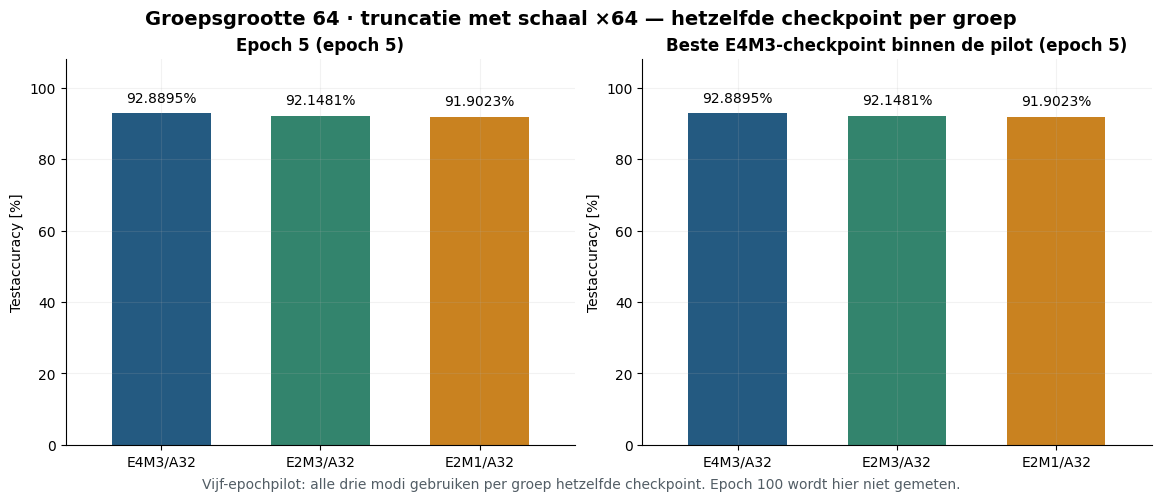

In [3]:
display(ns.checkpoint_table(run).round({'Testaccuracy [%]': 6, 'Harde test-CE': 8}))
figures['checkpoint_accuracy'] = ns.plot_checkpoint_accuracy(run)
display(figures['checkpoint_accuracy'])
plt.close(figures['checkpoint_accuracy'])


## Vergelijking met groepsgroottes 32 en 16: vaste ×64 en dezelfde vroege epochs

De ongewijzigde B32/×64- en B16/×64-referenties bevatten hun voltooide honderd-epochtrainingen. Hieronder worden **uitsluitend epochs 1 tot en met 5** gebruikt. De curves stoppen bij de laatste beschikbare B64-epoch. De epoch-5-vergelijking verschijnt pas wanneer B64 epoch 5 bereikt heeft. De afzonderlijke eerdere B16-pilot wordt niet gebruikt als referentie voor deze vergelijking.

Voor de beste-checkpointvergelijking selecteert E4M3 per training één epoch **binnen de gezamenlijke vroege epochrange**. Alle drie modi horen bij dat ene checkpoint. De globale beste epochs 42 (B32) en 53 (B16), en epoch 100 van die runs, zijn geen pilotcheckpoints. Referentiehashes, oorspronkelijke initialisatie en trainingsinstellingen worden gecontroleerd. De bedoelde experimentele wijziging is de groepsgrootte; de factor blijft ×64.


### Groepsgroottes 64, 32 en 16 met dezelfde vaste ×64

De B32- en B16-cijfers komen uit de eerste vijf epochs van hun bestaande honderd-epochtrainingen. De afzonderlijke eerdere B16-pilot wordt hier niet gebruikt. De globale beste epochs en epoch 100 van die runs blijven buiten de pilotvergelijking. E4M3 kiest per training één checkpoint binnen de gezamenlijke vroege epochrange; alle drie scores komen vervolgens uit diezelfde epoch. 

**Vergelijking met B32, B16 beschikbaar voor epochs 1–5.** Dezelfde oorspronkelijke modelstaat, seed en trainingsinstellingen zijn bevestigd, afgezien van de groepsgrootte en de pilotduur. Alle varianten gebruiken vaste ×64. Dit garandeert geen bitexacte CUDA-herhaalbaarheid. Vijf epochs bepalen niet welke groepsgrootte na honderd epochs het beste presteert.

,Controlepunt,Groepsgrootte,Epoch,Gewichtsformaat,Testaccuracy [%],Correct / n,Harde test-CE,Verschil B64 − referentie [pp]
0,Epoch 5,64,5,MXFP8_E4M3,92.889521,24.181 / 26.032,0.244672,NaN
1,Epoch 5,32,5,MXFP8_E4M3,93.008605,24.212 / 26.032,0.243082,-0.119084
2,Epoch 5,16,5,MXFP8_E4M3,93.054702,24.224 / 26.032,0.242750,-0.165181
3,Epoch 5,64,5,MXFP6_E2M3,92.148125,23.988 / 26.032,0.271322,NaN
4,Epoch 5,32,5,MXFP6_E2M3,91.299170,23.767 / 26.032,0.298985,0.848955
5,Epoch 5,16,5,MXFP6_E2M3,91.452827,23.807 / 26.032,0.292823,0.695298
6,Epoch 5,64,5,MXFP4_E2M1,91.902274,23.924 / 26.032,0.278697,NaN
7,Epoch 5,32,5,MXFP4_E2M1,90.891979,23.661 / 26.032,0.310513,1.010295
8,Epoch 5,16,5,MXFP4_E2M1,91.560387,23.835 / 26.032,0.286399,0.341887
9,Beste E4M3 binnen epochs 1–5,64,5,MXFP8_E4M3,92.889521,24.181 / 26.032,0.244672,NaN


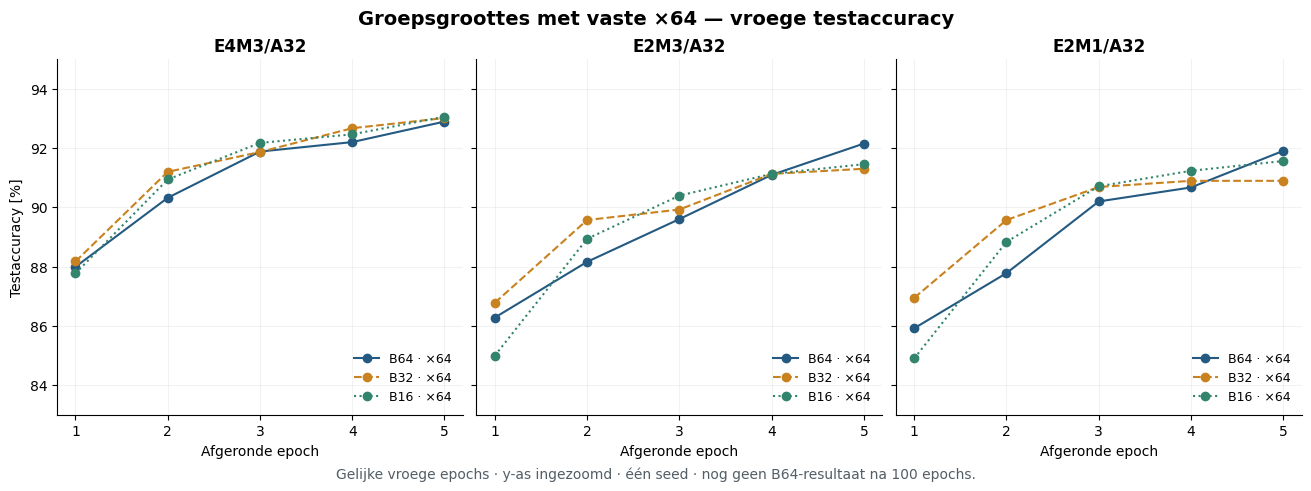

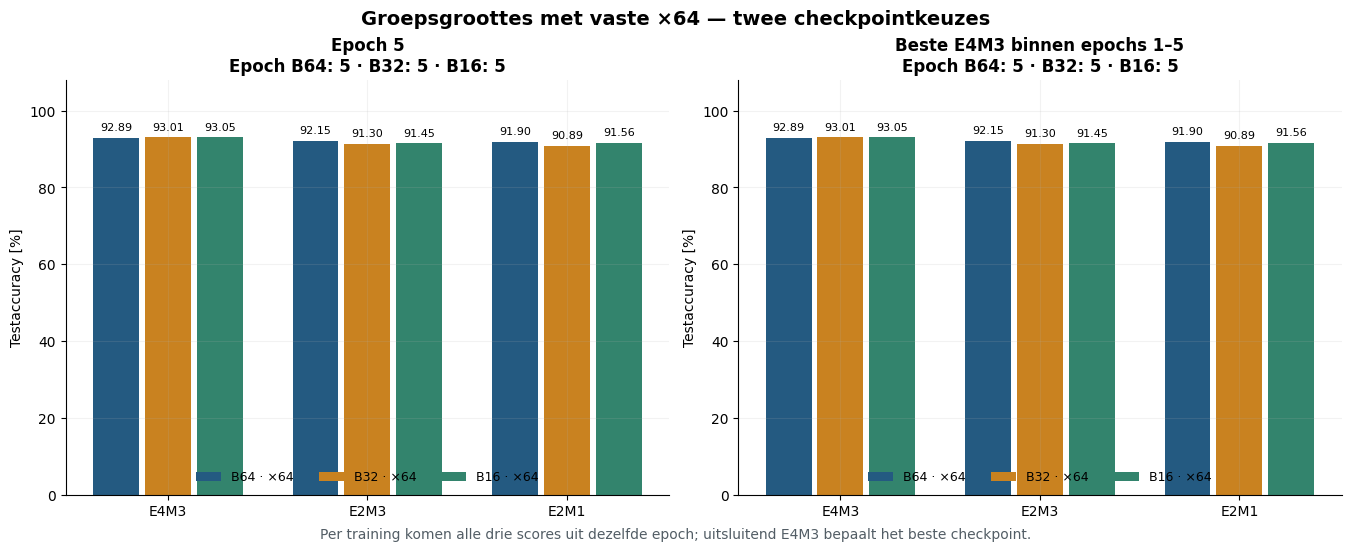

In [4]:
references = ns.load_group_references(run)
display(Markdown(ns.comparison_markdown(run, references)))
display(ns.comparison_table(run, references).round(6))
figures['group_comparison_curves'] = ns.plot_scale_comparison_curves(run, references)
display(figures['group_comparison_curves'])
plt.close(figures['group_comparison_curves'])
figures['group_comparison_checkpoints'] = ns.plot_scale_comparison_checkpoints(run, references)
display(figures['group_comparison_checkpoints'])
plt.close(figures['group_comparison_checkpoints'])


## Kosten: aantal schalen, padding en totale opslag

Elke groep heeft één E8M0-schaal van acht bits. Zonder padding kost de schaal $8/B$ bits per gewicht: 0,5 voor B16, 0,25 voor B32 en 0,125 voor B64. Onze implementatie groepeert echter per outputrij en vult elke rij tot een veelvoud van B aan.

De berekening gebeurt per laag en per precisie. Voor E4M3 tonen we ook de afzonderlijke overhead van schaalbytes en paddingcodes bovenop de reële gewichtswaarden. Dit maakt zichtbaar waarom **B64 in dit netwerk minder schalen maar toch meer bronopslag dan B32 heeft**: de grootste laag heeft 800 gewichten per outputrij, wat bij B64 wordt aangevuld tot 832; bij B16 en B32 past de rij exact.


Het opgeslagen geometrische kostenrapport is opnieuw berekend en bevestigd. Voor **6 van de 6** verwachte exporttabellen (drie precisies × beste/laatste checkpoint) zijn de gerapporteerde B64-groepen, padding en payload bevestigd.

De totalen betreffen uitsluitend de **129.472 reële gewichten in de zes MX-lagen**. E4M3 is de opgeslagen bron; E2M3/E2M1 zijn afzonderlijke mogelijke afgeleide exports. **Tel de drie payloadgroottes niet bij elkaar op als de opslag van één bronmodel.** Elke groep heeft één gedeelde schaal van acht bits; bij de vaste ×64-correctie wordt geen geleerde keuze per groep opgeslagen.

Zonder padding is de schaaloverhead $8/B$ bits per gewicht. Met onze groepering wordt elke outputrij apart aangevuld. Daarom gebruikt B64 ondanks minder schalen meer totale bronopslag dan B32: in de grootste laag worden 800 posities per rij bij B64 aangevuld tot 832, terwijl 16 en 32 exact passen.

De kosten voor alle drie groepsgroottes zijn geometrisch berekend; accuracy komt uitsluitend uit bevestigde trainingsmetingen. FP32-uitzonderingen/BatchNorm, optimizer, bestandsmetadata en emulatorbuffers zijn uitgesloten. Deze logische bytes zijn geen checkpointbestandsgrootte, GPU-geheugenmeting, hardwarelooptijd of energiemeting.

,Groepsgrootte,Reële gewichten,Groepen / schalen,Paddingposities,Schaalbytes,Schaalbits/gewicht zonder padding,E4M3 bron + schalen [bytes],E2M3 + schalen [bytes],E2M1 + schalen [bytes],E4M3 effectieve bits/reëel gewicht,E2M3 effectieve bits/reëel gewicht,E2M1 effectieve bits/reëel gewicht
0,16,129472,8096,64,8096,0.500,137632,105248,72864,8.504202,6.503213,4.502224
1,32,129472,4080,1088,4080,0.250,134640,102000,69360,8.319328,6.302521,4.285714
2,64,129472,2160,8768,2160,0.125,140400,105840,71280,8.675235,6.539792,4.404350


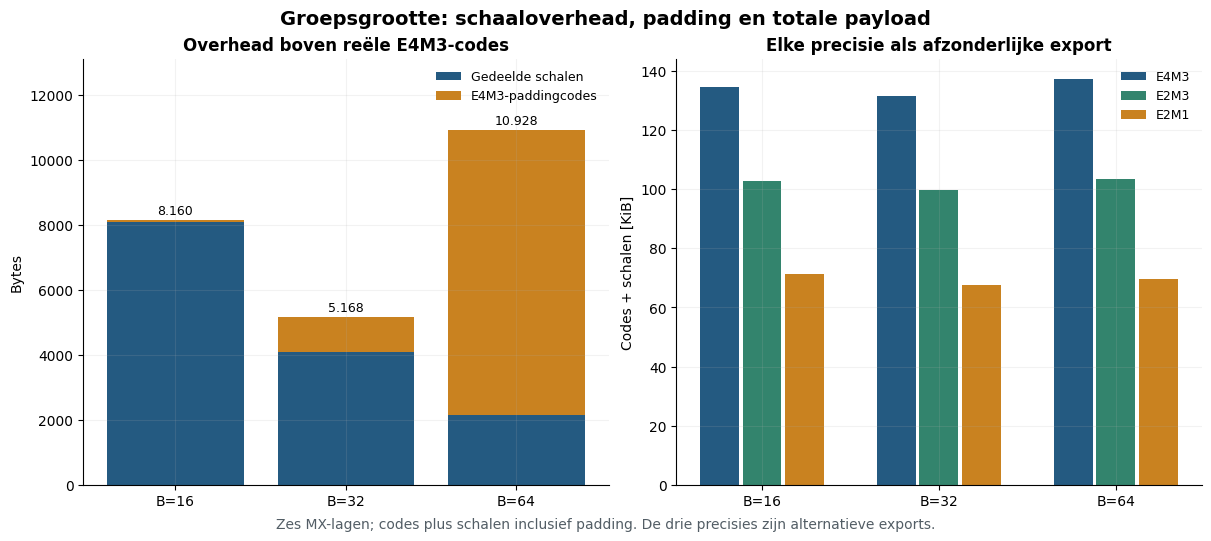

In [5]:
display(Markdown(ns.cost_markdown(run)))
display(ns.cost_summary_table(run).round(6))
figures['group_size_costs'] = ns.plot_group_costs(run)
display(figures['group_size_costs'])
plt.close(figures['group_size_costs'])


### Kosten per laag en controle tegen de opgeslagen exports

De eerste tabel geeft de berekende E4M3-bronindeling per laag bij B16/B32/B64. De lagere precisies worden met dezelfde groepsgeometrie afzonderlijk berekend. `group_size_costs_layers.csv` bevat alle lagen en alle drie de precisies.

De tweede tabel controleert B64 tegen de opgeslagen exportdiagnostiek op het beste en laatste checkpoint. Deze controle bevestigt gerapporteerde aantallen; de codec- en exporttests van de runner controleren daarnaast de werkelijke codebytes en gereconstrueerde gewichten.


In [6]:
display(ns.cost_layer_table(run, weight_bits=8))
display(ns.export_layout_table(run))


,B,Laag,Vorm,Gewichten/rij,Opgeslagen/rij,Reële gewichten,Groepen,Paddingposities,Codebytes,Schaalbytes,Code + schaal [bytes]
0,16,layers.3,"[16, 12, 3, 3]",108,112,1728,112,64,1792,112,1904
1,16,layers.6,"[16, 16, 3, 3]",144,144,2304,144,0,2304,144,2448
2,16,layers.10,"[32, 16, 3, 3]",144,144,4608,288,0,4608,288,4896
3,16,layers.13,"[32, 32, 3, 3]",288,288,9216,576,0,9216,576,9792
4,16,layers.16,"[32, 32, 3, 3]",288,288,9216,576,0,9216,576,9792
5,16,layers.20,"[128, 32, 5, 5]",800,800,102400,6400,0,102400,6400,108800
6,32,layers.3,"[16, 12, 3, 3]",108,128,1728,64,320,2048,64,2112
7,32,layers.6,"[16, 16, 3, 3]",144,160,2304,80,256,2560,80,2640
8,32,layers.10,"[32, 16, 3, 3]",144,160,4608,160,512,5120,160,5280
9,32,layers.13,"[32, 32, 3, 3]",288,288,9216,288,0,9216,288,9504


,status,reported_layout_verified,group_size,weight_bits,layers,n_weights,blocks,padded_slots,packed_weight_and_scale_bytes,role,epoch
0,PASS,True,64,8,6,129472,2160,8768,140400,best,5
1,PASS,True,64,6,6,129472,2160,8768,105840,best,5
2,PASS,True,64,4,6,129472,2160,8768,71280,best,5
3,PASS,True,64,8,6,129472,2160,8768,140400,last,5
4,PASS,True,64,6,6,129472,2160,8768,105840,last,5
5,PASS,True,64,4,6,129472,2160,8768,71280,last,5


## Kwantisatiefout op de twee geselecteerde checkpoints

De opgeslagen exportdiagnostiek vergelijkt de gecodeerde gewichten met de effectieve FP32-gewichten G(W), zonder een nieuwe evaluatie te starten. RMSE wordt gewogen over de reële gewichten van de zes MX-lagen; padding telt niet mee. Nieuwe nulwaarden zijn gewichten die vóór kwantisatie niet nul waren en daarna nul worden. Dit is gewichtsdiagnostiek, geen vervanging voor testaccuracy.


,checkpoint_role,checkpoint_epoch,weight_bits,layer,n_weights,mae,rmse,relative_l2,max_abs_error,new_zero_count,local_subnormal_count,out_of_element_range_before_round,scale_exponent_min,scale_exponent_max,padded_slots
0,best,5,8,layers.3,1728,0.000831,0.001348,0.038629,0.006110,0,0,255,-13,-13,320
1,best,5,8,layers.6,2304,0.000671,0.001021,0.030344,0.004708,0,0,207,-13,-13,768
2,best,5,8,layers.10,4608,0.000728,0.001202,0.036091,0.006383,0,0,454,-13,-13,1536
3,best,5,8,layers.13,9216,0.000494,0.000701,0.026012,0.001951,0,0,0,-13,-13,1024
4,best,5,8,layers.16,9216,0.000449,0.000656,0.026216,0.001952,0,0,0,-13,-13,1024
5,best,5,8,layers.20,102400,0.000231,0.000370,0.028322,0.003904,0,9,452,-16,-13,4096
6,best,5,6,layers.3,1728,0.015258,0.021027,0.602697,0.051458,0,0,56,-7,-7,320
7,best,5,6,layers.6,2304,0.015781,0.021685,0.644791,0.051513,0,1,14,-7,-7,768
8,best,5,6,layers.10,4608,0.016103,0.021665,0.650502,0.051508,0,5,120,-7,-7,1536
9,best,5,6,layers.13,9216,0.018943,0.023774,0.882244,0.051511,2,3,0,-7,-7,1024


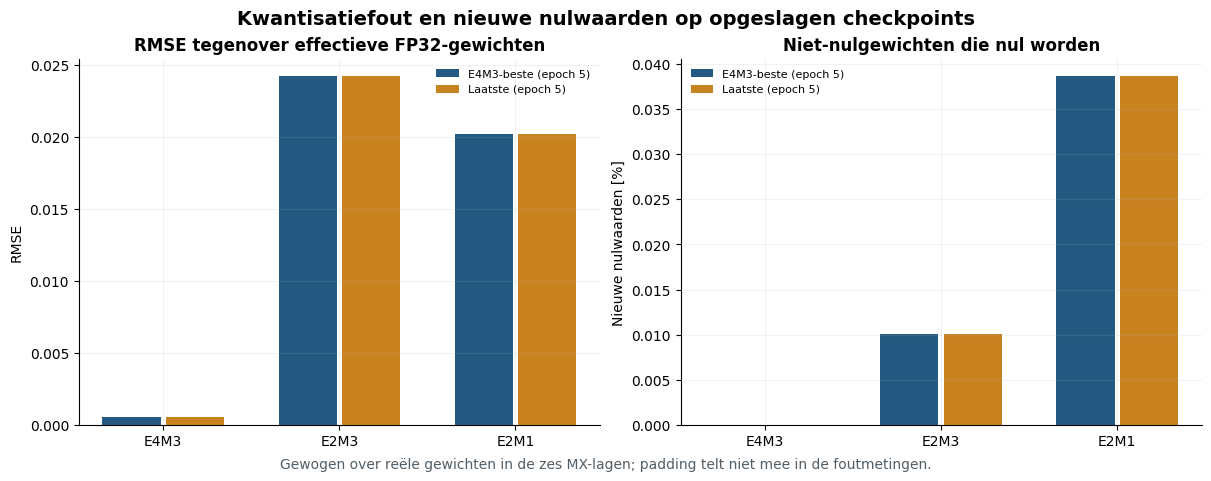

In [7]:
display(ns.quantization_table(run))
figures['quantization_diagnostics'] = ns.plot_quantization(run)
display(figures['quantization_diagnostics'])
plt.close(figures['quantization_diagnostics'])


## Train- en testaccuracy per modus

De drie modi worden gezamenlijk vanaf dezelfde oorspronkelijke initialisatie getraind. Trainaccuracy wordt tijdens de updates verzameld. Testaccuracy wordt na iedere epoch gemeten met B64 en dezelfde ×64-truncatieroute, bevroren evaluatiestaat en de volledige testset. De drie modusgebonden BatchNorm-banken leren tijdens de training normaal mee.


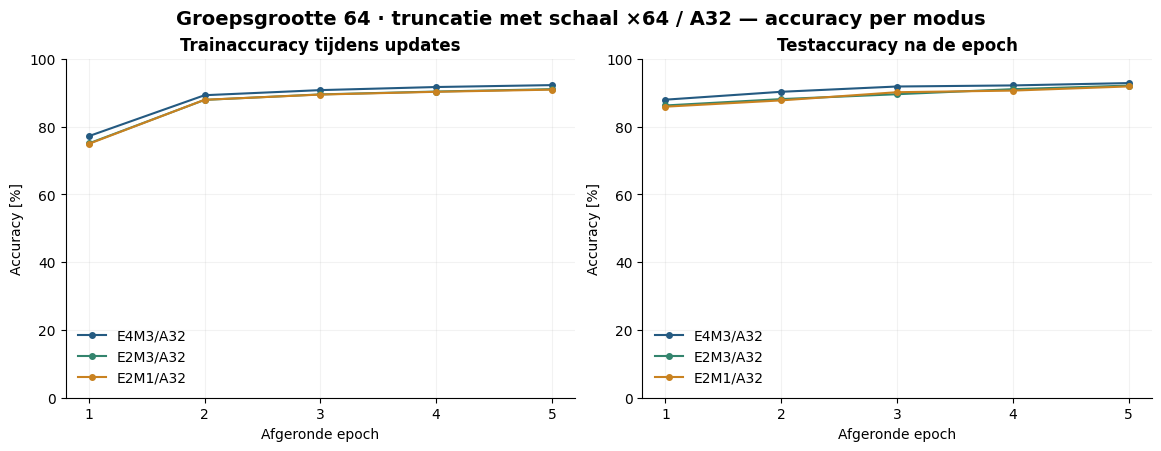

In [8]:
figures['accuracy_curves'] = ns.plot_learning(run)
display(figures['accuracy_curves'])
plt.close(figures['accuracy_curves'])


## Losses: trainingsdoelen onderscheiden van harde test-CE

De trainpass van E4M3 gebruikt harde CE van labels. Daarna leert E2M3 met soft-target CE van de **detached E4M3-softmax**; E2M1 leert met soft-target CE van de **detached E2M3-softmax**. Dit is recursieve distillatie met T=1. De drie gradients worden gesommeerd zonder deling door drie, waarna één Adam-update volgt; er is geen extra FP32-teacherforward.

De drie trainobjectieven staan in afzonderlijke panelen omdat hun targets verschillen. Soft CE is geen harde label-CE en wordt hier ook niet als KL-divergentie aangeduid. **Testloss is voor alle drie modi harde CE van dezelfde labels** en staat daarom samen in één vergelijkbaar paneel.


,epoch,phase,weight_format,objective_type,objective_loss
0,1,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.945649
1,1,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.918024
2,1,train,MXFP8_E4M3,hard_cross_entropy,0.715832
3,1,test,MXFP4_E2M1,hard_cross_entropy,0.469233
4,1,test,MXFP6_E2M3,hard_cross_entropy,0.446210
5,1,test,MXFP8_E4M3,hard_cross_entropy,0.391113
6,2,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.516275
7,2,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.462751
8,2,train,MXFP8_E4M3,hard_cross_entropy,0.352317
9,2,test,MXFP4_E2M1,hard_cross_entropy,0.425636


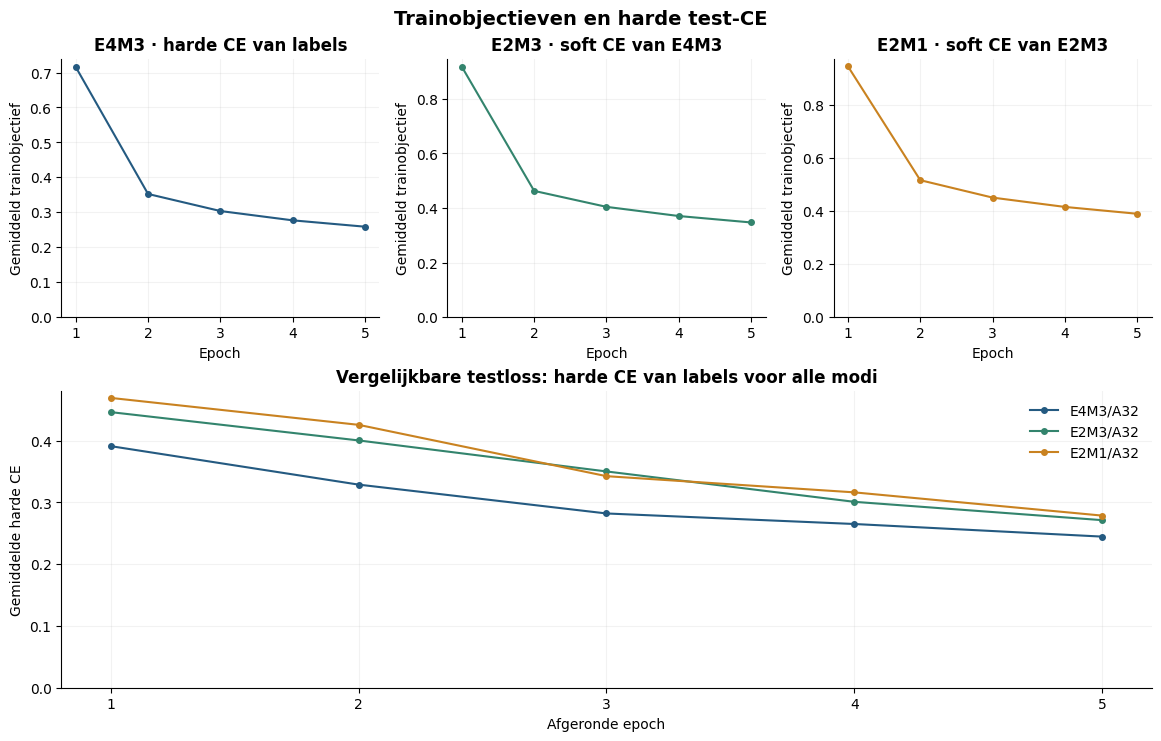

In [9]:
if not run.metrics.empty:
    objective_columns = [key for key in ('epoch', 'phase', 'weight_format', 'objective_type', 'objective_loss') if key in run.metrics]
    display(run.metrics[objective_columns].round({'objective_loss': 8}))
figures['objective_losses'] = ns.plot_objectives(run)
display(figures['objective_losses'])
plt.close(figures['objective_losses'])


## Blijft het netwerk verschillende cijfers voorspellen?

De eerdere post-hocproeven lieten bij sommige routes sterk vertekende of constante voorspellingen zien. Daarom wordt hier per testepoch en per modus bijgehouden hoe de voorspellingen over de tien cijfers verdeeld zijn. Een constante voorspelling is direct zichtbaar als **één gebruikte klasse en 100% concentratie**. De tabel toont ook hoe vaak het dominante cijfer werkelijk in de testset voorkomt.

Dit zijn geaggregeerde tellingen; deze notebook doet geen nieuwe inferentie en leidt er geen per-beeldvergelijking uit af.


,Rol,Epoch,Gewichtsformaat,Voorspelde klassen,Meest voorspelde cijfer,Aandeel dominant cijfer [%],Aandeel dat cijfer in labels [%],Testaccuracy [%],Constante voorspelling,Testbeelden,Tellingen voorspeld cijfer 0..9,Tellingen echt cijfer 0..9
0,last_epoch,5,MXFP8_E4M3,10,1,20.190535,19.587431,92.889521,False,26032,"[1788, 5256, 4155, 2839, 2449, 2272, 2049, 199...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
1,last_epoch,5,MXFP6_E2M3,10,1,20.144438,19.587431,92.148125,False,26032,"[1824, 5244, 4140, 2833, 2463, 2259, 2127, 201...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
2,last_epoch,5,MXFP4_E2M1,10,1,20.175169,19.587431,91.902274,False,26032,"[1834, 5252, 4151, 2797, 2457, 2281, 2133, 202...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
3,best_E4M3_test,5,MXFP8_E4M3,10,1,20.190535,19.587431,92.889521,False,26032,"[1788, 5256, 4155, 2839, 2449, 2272, 2049, 199...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
4,best_E4M3_test,5,MXFP6_E2M3,10,1,20.144438,19.587431,92.148125,False,26032,"[1824, 5244, 4140, 2833, 2463, 2259, 2127, 201...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
5,best_E4M3_test,5,MXFP4_E2M1,10,1,20.175169,19.587431,91.902274,False,26032,"[1834, 5252, 4151, 2797, 2457, 2281, 2133, 202...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."


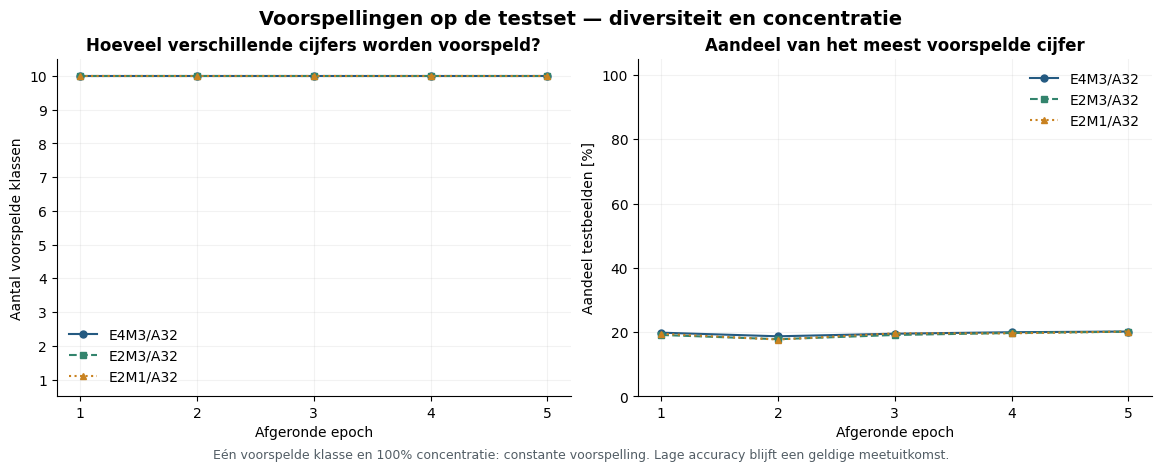

In [10]:
display(ns.prediction_table(run, selected_only=True))
figures['prediction_diversity'] = ns.plot_prediction_diversity(run)
display(figures['prediction_diversity'])
plt.close(figures['prediction_diversity'])


## Gemeten trainingsduur en voorlopige projectie naar honderd epochs

**Gemeten som over 5 afgeronde epochs: 315.95 s (5.27 minuten).** Warme epochs volgens het tijdsrapport: **[2, 3, 4, 5]**; mediaan: **63.4 s**. De afzonderlijke projectie geldt voor een **nieuwe volledige run van honderd epochs vanaf initialisatie**. Zij is geen gemeten eindtijd en geen resterende hervattijd. Het waargenomen minimum/maximum van de warme epochs levert een scenario-bereik, geen betrouwbaarheidsinterval. Vijf epochs meten de LR-overgangen op 50/75/90 en langdurige thermische omstandigheden nog niet. Download, installatie, data-inladen en eindrapportage zijn niet inbegrepen. **Geen accuracy voor epoch100 wordt voorspeld.**

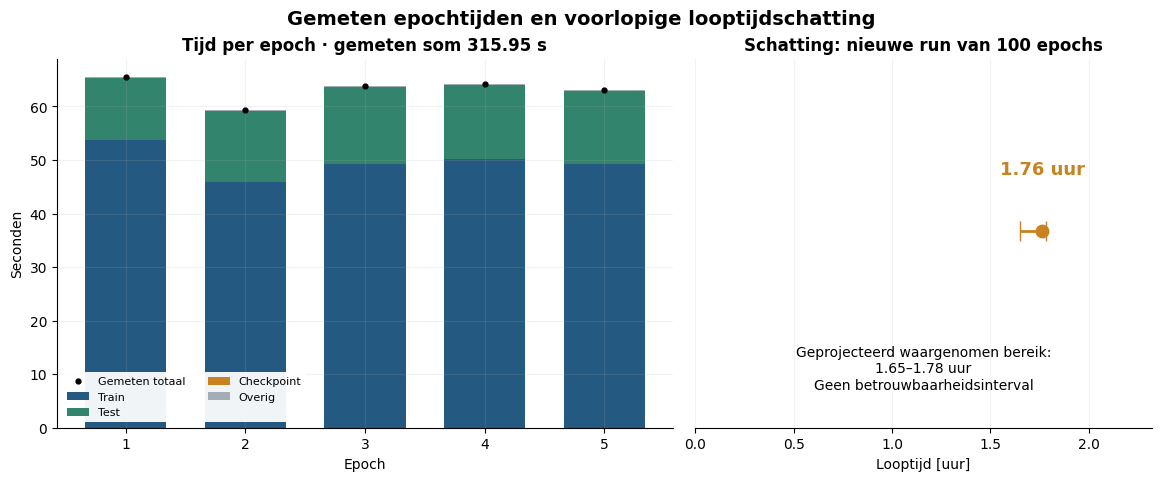

In [11]:
display(Markdown('## Gemeten trainingsduur en voorlopige projectie naar honderd epochs'))
display(Markdown(ns.timing_markdown(run)))
figures['timing'] = ns.plot_timing(run)
display(figures['timing'])
plt.close(figures['timing'])


## GPU-geheugen

De opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.

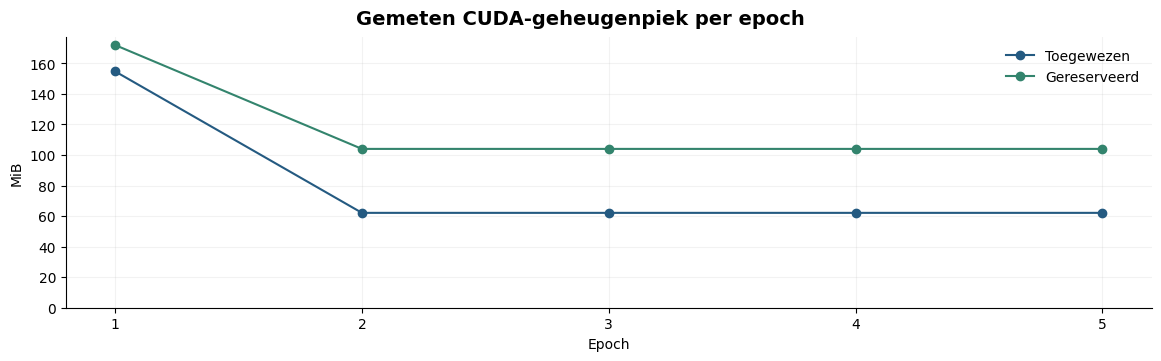

In [12]:
display(Markdown('## GPU-geheugen\n\nDe opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.'))
figures['gpu_memory'] = ns.plot_memory(run)
display(figures['gpu_memory'])
plt.close(figures['gpu_memory'])


In [13]:
display(Markdown('## Opgeslagen technische controles\n\nDeze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.'))
display(ns.audit_table(run))
display(Markdown('### Gewichtsupdates\n\nDe mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.'))
display(ns.weight_update_table(run))
display(Markdown('### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint'))
display(ns.export_table(run))


## Opgeslagen technische controles

Deze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.

,Opgeslagen controle,Resultaat volgens rapport
0,Gradientcontrole vóór iedere gezamenlijke update,True
1,FP32-masters en Adam-momenten geverifieerd,True
2,Lagere schaalcodes exact E4-bron +6,True
3,E2M1 behoudt de E2M3-schaalbytes,True
4,Eén E4-bron per laag per minibatch,True
5,Broncache leeg vóór iedere optimizerupdate,True
6,BN-tellers van alle opgeslagen epochs correct,True
7,Geen optimizerupdates tijdens evaluatie,True
8,Bronbestanden onveranderd,True
9,Ruwe datasetbestanden onveranderd,True


### Gewichtsupdates

De mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.

,epoch,weight_format,layer,master_changed_values,master_update_l2,master_dtype,changed_element_codes_including_padding,changed_scale_codes
0,1,MXFP4_E2M1,layers.3,1728,1.443113,torch.float32,1076,0
1,1,MXFP6_E2M3,layers.3,1728,1.443113,torch.float32,1528,0
2,1,MXFP8_E4M3,layers.3,1728,1.443113,torch.float32,1597,0
3,1,MXFP4_E2M1,layers.6,2304,1.686615,torch.float32,1400,0
4,1,MXFP6_E2M3,layers.6,2304,1.686615,torch.float32,2066,0
...,...,...,...,...,...,...,...,...
85,5,MXFP6_E2M3,layers.16,9216,1.381376,torch.float32,8014,0
86,5,MXFP8_E4M3,layers.16,9216,1.381376,torch.float32,8205,0
87,5,MXFP4_E2M1,layers.20,102378,5.457271,torch.float32,58634,360
88,5,MXFP6_E2M3,layers.20,102378,5.457271,torch.float32,90510,360


### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint

,Rol,Epoch,Gewichtsformaat,Bestand,Bestandsbytes,Gewichten exact gereconstrueerd,Zes FP32-masters afwezig,Volledige exporttest opnieuw,Truncatie,Bron of afleiding,E4-bronschaalbytes behouden,Schaalexponentoffset tegenover E4,Schaalfactor tegenover E4,Masters gelezen voor afleiding,Opgeslagen en herladen,Bronbestand-SHA256
0,best_E4M3_test,5,MXFP8_E4M3,mx_source_MXFP8_E4M3_best.pt,202533,True,True,False,False,E4M3-bron,True,0,1,False,True,b421176e8ea2728ed7dbfd1dae69d4997d01af7116f08a...
1,best_E4M3_test,5,MXFP6_E2M3,mx_derived_MXFP6_E2M3_best.pt,168613,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,6,64,False,True,b421176e8ea2728ed7dbfd1dae69d4997d01af7116f08a...
2,best_E4M3_test,5,MXFP4_E2M1,mx_derived_MXFP4_E2M1_best.pt,134053,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,6,64,False,True,b421176e8ea2728ed7dbfd1dae69d4997d01af7116f08a...
3,last_epoch,5,MXFP8_E4M3,mx_source_MXFP8_E4M3_last.pt,202533,True,True,False,False,E4M3-bron,True,0,1,False,True,b421176e8ea2728ed7dbfd1dae69d4997d01af7116f08a...
4,last_epoch,5,MXFP6_E2M3,mx_derived_MXFP6_E2M3_last.pt,168613,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,6,64,False,True,b421176e8ea2728ed7dbfd1dae69d4997d01af7116f08a...
5,last_epoch,5,MXFP4_E2M1,mx_derived_MXFP4_E2M1_last.pt,134053,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,6,64,False,True,b421176e8ea2728ed7dbfd1dae69d4997d01af7116f08a...


## Interpretatie en grenzen

De gerichte wijziging is **groepsgrootte 64**, tegenover de bestaande referenties B32 en B16. De factor blijft ×64, de mantissatruncatie behoudt de E2M3-schaal, en de overige trainingsinstellingen en initiële mastergewichten komen overeen. Er is geen directe lagere kwantisatie, geleerde schaal of extra FP32-teacherpass. De identity-STE geldt voor de volledige codebewerking naar G(W), zonder extra factor64 in de backward.

Een lage accuracy blijft een onderzoeksuitkomst wanneer de technische controles slagen. Een dalende soft-target trainingsloss bewijst op zichzelf geen betere classificatie; bekijk testaccuracy, harde test-CE en voorspellingstellingen samen. Kleinere groepen kunnen een gunstigere lokale schaal opleveren, maar garanderen geen hogere netwerkaccuracy. De bestaande B16-honderd-epochrun illustreert waarom een gunstig vroeg pilotresultaat niet automatisch doorzet tot epoch 100.

De oorspronkelijke cuDNN-backend garandeert geen bitexacte CUDA-herhaalbaarheid. Deze proef heeft één seed en vijf epochs; een klein verschil bewijst geen algemene superioriteit of optimale groepsgrootte. De beste E4M3-score selecteert op de officiële testset en is geen onafhankelijke testschatting.

**Kosten horen bij de conclusie:** meer groepen betekenen meer schaalbytes, terwijl grotere groepen bij onze rijindeling meer padding kunnen veroorzaken. Rapporteer daarom zowel schaaloverhead als totale payload. De drie exportgroottes zijn alternatieven; één E4M3-bronmodel wordt niet driemaal geteld. Logische payload, checkpointbestandsgrootte en gemeten GPU-geheugen zijn verschillende grootheden.

De tijdprojectie voor honderd epochs is uitsluitend een looptijdschatting. Er wordt geen accuracy voor epoch 100 berekend. De geheugenfiguur betreft de CUDA-allocator van de FP32-emulator en meet geen native MX-kernel, hardwareversnelling of energiewinst.


In [14]:
if SAVE_FIGURES:
    analysis_dir = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', analysis_dir)
else:
    print('Alleen analyse in het notebook; geen figuren naar schijf geschreven.')
print('Ingelezen resultaatmap:', run.path)
display(pd.DataFrame({'Ingelezen bestand': [str(path.relative_to(run.path)) if path.is_relative_to(run.path) else str(path) for path in run.input_files]}))


Alleen analyse in het notebook; geen figuren naar schijf geschreven.
Ingelezen resultaatmap: C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_group64_scale64_pilot5\20261027_170656_785350_joint_run


,Ingelezen bestand
0,run_report.json
1,history.json
2,training_summary.json
3,checkpoint_selection.json
4,timing_estimate.json
5,epoch_metrics.csv
6,selected_metrics.csv
7,epoch_times.csv
8,weight_updates.csv
9,group_size_costs.json
